# Итоговый проект. Анализ покупателей спортивного магазина

Исследование пройдёт по следующим этапам: знакомство с данными → подготовка → восстановление пола → A/B-тест → кластеризация → прогноз покупки.

## Знакомство с файлами

Посмотрим структуру базы данных и содержимое таблиц

In [1]:
import sqlite3
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, chisquare, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, roc_auc_score, silhouette_score
from IPython.display import display

pd.set_option('display.max_columns', 30)

In [2]:
def show_missing(data, title):
    print(title)
    display(data.isna().sum())


def plot_bar(labels, values, title, xlabel, ylabel):
    plt.figure(figsize=(6, 3.5))
    plt.bar(labels, values)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

In [3]:
connection = sqlite3.connect('shop_database.db')
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", connection)
display(tables)

,name
0,purchases
1,personal_data_coeffs
2,personal_data


In [4]:
for table_name in ['personal_data', 'personal_data_coeffs', 'purchases']:
    print('Таблица:', table_name)
    display(pd.read_sql_query(f'SELECT * FROM {table_name} LIMIT 5', connection))

Таблица: personal_data


,id,gender,age,education,city,country
0,0,0,36,среднее,1201,32
1,4,0,35,среднее,1134,32
2,6,1,52,среднее,1188,32
3,7,0,37,среднее,1198,32
4,9,0,48,среднее,1134,32


Таблица: personal_data_coeffs


,id,lbt_coef,ac_coef,sm_coef,personal_coef
0,0,5.078678,-0.307147,0.959027,0.5072
1,3,7.764766,-0.030225,0.794720,0.4304
2,4,4.569378,0.063693,0.820892,0.5072
3,6,8.150379,0.075200,0.836140,0.4304
4,7,5.188231,-0.000134,0.944113,0.5072


Таблица: purchases


,id,product,colour,cost,product_sex,base_sale,dt
0,0,"Велосипед горный женский Stern Mira 2.0 26""",белый/синий,13599,0.0,1,7
1,0,Стол Outventure,зелёный,1499,NaN,0,37
2,0,Набор Outventure: стол + 4 стула,бежевый,4799,NaN,0,37
3,3,Бутсы мужские GSD Astro,белый,1599,1.0,0,13
4,3,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мультицвет,7199,NaN,0,27


Загрузим данные и проверим размеры таблиц и пропуски.

In [5]:
personal = pd.read_sql_query('SELECT * FROM personal_data', connection)
coefficients = pd.read_sql_query('SELECT id, personal_coef FROM personal_data_coeffs', connection)
purchases = pd.read_sql_query('SELECT * FROM purchases', connection)
connection.close()

missing_profiles = pd.read_csv('personal_data.csv.gz')
print('Профили из базы:', personal.shape)
print('Профили из CSV:', missing_profiles.shape)
print('Коэффициенты:', coefficients.shape)
print('Покупки:', purchases.shape)

Профили из базы: (89241, 6)
Профили из CSV: (15748, 5)
Коэффициенты: (104989, 2)
Покупки: (786260, 7)


In [6]:
show_missing(personal, 'Пропуски в базе профилей:')
show_missing(purchases, 'Пропуски в покупках:')

print('Пример восстановленных профилей:')
display(missing_profiles.head())

Пропуски в базе профилей:


id           0
gender       0
age          0
education    0
city         0
country      0
dtype: int64

Пропуски в покупках:


id                  0
product             0
colour         119524
cost                0
product_sex    314712
base_sale           0
dt                  0
dtype: int64

Пример восстановленных профилей:


,id,age,education,city,country
0,101492,32,среднее,1188,32
1,42690,20,высшее,1134,32
2,113001,27,среднее,1187,32
3,163654,49,высшее,1160,32
4,69523,44,среднее,1137,32


In [7]:
for name, table in [
    ('профилях базы', personal),
    ('отдельном CSV', missing_profiles),
    ('коэффициентах', coefficients)
]:
    print('Повторяющиеся ID в', name + ':', table['id'].duplicated().sum())

print('\nЧисло неположительных стоимостей:', (purchases.cost <= 0).sum())
print('\nСтраны в базе:', personal.country.value_counts().head())

Повторяющиеся ID в профилях базы: 0
Повторяющиеся ID в отдельном CSV: 0
Повторяющиеся ID в коэффициентах: 0

Число неположительных стоимостей: 4

Страны в базе: country
32    88786
35      255
38       72
5        30
0        29
Name: count, dtype: int64


In [8]:
second_csv = pd.read_csv('personal_data.csv')
print('Два CSV содержат одинаковые данные:', missing_profiles.equals(second_csv))

Два CSV содержат одинаковые данные: True


## Объединение и предобработка

Отдельный CSV содержит недостающие профили без поля `gender`. Добавим их к основной таблице, оставим страну 32 и присоединим `personal_coef`.

In [9]:
missing_profiles['gender'] = np.nan
clients = pd.concat([personal, missing_profiles], ignore_index=True)

print('Всего профилей до фильтрации:', len(clients))
print('Дубликатов ID после объединения:', clients.id.duplicated().sum())

Всего профилей до фильтрации: 104989
Дубликатов ID после объединения: 0


In [10]:
clients = clients[clients['country'] == 32].copy()
clients = clients.merge(coefficients, on='id', how='left')

print('Клиенты страны 32:', len(clients))
print('Пол известен:', clients.gender.notna().sum())
print('Пол не известен:', clients.gender.isna().sum())

show_missing(clients, 'Пропуски после объединения профилей:')

Клиенты страны 32: 104437
Пол известен: 88786
Пол не известен: 15651
Пропуски после объединения профилей:


id                   0
gender           15651
age                  0
education            0
city                 0
country              0
personal_coef        0
dtype: int64

Проверим названия и цвета товаров. Названия приводим к нижнему регистру, убираем лишние пробелы. Если цвет записан через `/`, используем первый цвет для сравнения, но исходное название цвета не теряем.

In [11]:
print('Примеры названий товаров:')
display(purchases['product'].value_counts().head(10))

print('Примеры цветов:')
display(purchases['colour'].value_counts().head(10))

Примеры названий товаров:


product
Брюки мужские Demix         4961
Шорты мужские Demix         4650
Футболка мужская Demix      3644
Лиф женский Joss            3378
Футболка женская Demix      3252
Брюки мужские Outventure    3132
Купальник женский Joss      2787
Брюки мужские FILA          2746
Плавки женские Joss         2585
Брюки женские Outventure    2443
Name: count, dtype: int64

Примеры цветов:


colour
черный          131399
белый            42520
чёрный           37022
синий            35268
темно-синий      27257
серый            26534
бежевый          24562
мультицвет       18219
черный/белый     11002
розовый           9564
Name: count, dtype: int64

In [12]:
purchases['product_clean'] = purchases['product'].str.lower().str.strip()
purchases['product_clean'] = purchases['product_clean'].str.replace('ё', 'е', regex=False)
purchases['product_clean'] = purchases['product_clean'].str.replace(r'\s+', ' ', regex=True)
purchases['category'] = purchases['product_clean'].str.split().str[0]

In [13]:
purchases['colour_clean'] = purchases['colour'].fillna('не указан').str.lower().str.strip()
purchases['colour_clean'] = purchases['colour_clean'].str.replace('ё', 'е', regex=False)
purchases['colour_clean'] = purchases['colour_clean'].str.split('/').str[0].str.strip()
purchases['product_sex'] = purchases['product_sex'].fillna(-1).astype(int)

display(purchases[['product', 'product_clean', 'category', 'colour', 'colour_clean']].head(8))

,product,product_clean,category,colour,colour_clean
0,"Велосипед горный женский Stern Mira 2.0 26""","велосипед горный женский stern mira 2.0 26""",велосипед,белый/синий,белый
1,Стол Outventure,стол outventure,стол,зелёный,зеленый
2,Набор Outventure: стол + 4 стула,набор outventure: стол + 4 стула,набор,бежевый,бежевый
3,Бутсы мужские GSD Astro,бутсы мужские gsd astro,бутсы,белый,белый
4,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мяч футбольный puma teamfinal 21.2 fifa qualit...,мяч,мультицвет,мультицвет
5,Кеды мужские FILA A-Low,кеды мужские fila a-low,кеды,белый,белый
6,Полуботинки мужские Outventure Chase,полуботинки мужские outventure chase,полуботинки,серый,серый
7,Роликовые коньки детские Roces Orlando III,роликовые коньки детские roces orlando iii,роликовые,черный/розовый,черный


In [14]:
country_purchases = purchases[purchases['id'].isin(clients['id'])].copy()
print('Покупки клиентов страны 32:', len(country_purchases))
print('Стоимость <= 0:', (country_purchases.cost <= 0).sum())

country_purchases = country_purchases[country_purchases['cost'] > 0].copy()
print('Строк покупок после обработки:', len(country_purchases))

Покупки клиентов страны 32: 780117
Стоимость <= 0: 4
Строк покупок после обработки: 780113


Вывод этапа: восстановленные профили объединены с базой, а страна 32 выделена до расчётов. Строки с неположительной стоимостью не включаем в анализ выручки.

## Восстановление пола

Рассчитаем признаки покупательского поведения для каждого клиента. Они пригодятся модели классификации.

In [15]:
country_purchases['male_item'] = (country_purchases['product_sex'] == 1).astype(int)
country_purchases['female_item'] = (country_purchases['product_sex'] == 0).astype(int)

client_stats = country_purchases.groupby('id').agg(
    purchase_count=('cost', 'size'),
    total_spend=('cost', 'sum'),
    avg_price=('cost', 'mean'),
    sale_share=('base_sale', 'mean'),
    male_items=('male_item', 'sum'),
    female_items=('female_item', 'sum'),
    last_day=('dt', 'max')
)

display(client_stats.head())

,purchase_count,total_spend,avg_price,sale_share,male_items,female_items,last_day
id,,,,,,,
0,3,19897,6632.333333,0.333333,0,1,37
3,4,14596,3649.000000,0.250000,3,0,34
4,7,31093,4441.857143,0.000000,0,0,32
6,15,84085,5605.666667,0.400000,9,0,30
7,13,58827,4525.153846,0.384615,0,5,49


In [16]:
client_stats['male_share'] = client_stats['male_items'] / client_stats['purchase_count']
client_stats['female_share'] = client_stats['female_items'] / client_stats['purchase_count']
clients = clients.merge(client_stats, left_on='id', right_index=True, how='left')

show_missing(clients, 'Пропуски после присоединения покупок:')

Пропуски после присоединения покупок:


id                    0
gender            15651
age                   0
education             0
city                  0
country               0
personal_coef         0
purchase_count        0
total_spend           0
avg_price             0
sale_share            0
male_items            0
female_items          0
last_day              0
male_share            0
female_share          0
dtype: int64

In [17]:
stat_columns = client_stats.columns
clients[stat_columns] = clients[stat_columns].fillna(0)
clients['higher_education'] = (clients['education'] == 'высшее').astype(int)

print('Клиенты с нулём покупок:', (clients.purchase_count == 0).sum())

Клиенты с нулём покупок: 0


Целевой признак – `gender` (0 или 1). Для проверки качества выделим 20% известных наблюдений, которые не будут участвовать в обучении.

In [18]:
gender_features = [
    'personal_coef', 'age', 'higher_education', 'purchase_count',
    'total_spend', 'avg_price', 'sale_share', 'male_share', 'female_share'
]

known = clients[clients['gender'].notna()].copy()
X = known[gender_features]
y = known['gender'].astype(int)

print('Распределение известных классов:')
print(y.value_counts())

Распределение известных классов:
gender
1    50910
0    37876
Name: count, dtype: int64


In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

Обучающая выборка: (71028, 9)
Тестовая выборка: (17758, 9)


In [20]:
gender_model = RandomForestClassifier(n_estimators=100, max_depth=11, min_samples_leaf=2, random_state=42, n_jobs=-1)
gender_model.fit(X_train, y_train)
gender_pred = gender_model.predict(X_test)

print('Точность:', round(accuracy_score(y_test, gender_pred), 4))
print('F1:', round(f1_score(y_test, gender_pred), 4))
print('Матрица ошибок:')
print(confusion_matrix(y_test, gender_pred))

Точность: 1.0
F1: 1.0
Матрица ошибок:
[[ 7576     0]
 [    0 10182]]


Модель проверена на отложенной выборке. Теперь заполним пропущенный пол, не изменяя известные значения.

In [21]:
clients['gender_restored'] = clients['gender'].copy()
missing_gender = clients['gender_restored'].isna()
clients.loc[missing_gender, 'gender_restored'] = gender_model.predict(
    clients.loc[missing_gender, gender_features]
)

clients['gender_restored'] = clients['gender_restored'].astype(int)
print('Восстановлено записей:', missing_gender.sum())
print('Осталось пропусков пола:', clients.gender_restored.isna().sum())

Восстановлено записей: 15651
Осталось пропусков пола: 0


In [22]:
print('Связь персонального коэффициента с полом:')
display(pd.crosstab(known['personal_coef'], known['gender']).head(12))

Связь персонального коэффициента с полом:


gender,0.0,1.0
personal_coef,,
0.2576,0,576
0.2672,0,3154
0.2768,426,0
0.2896,1320,0
0.4304,0,37008
0.4688,0,10172
0.5072,31529,0
0.5584,4601,0


Объединим обработанные покупки с полными профилями клиентов. Отдельно сохраним таблицу клиентов, поскольку она содержит и тех, кто не покупал.

In [23]:
profile_columns = ['id', 'gender_restored', 'age', 'education', 'city', 'country', 'personal_coef']
full_data = country_purchases.merge(clients[profile_columns], on='id', how='left')

print('Строк в итоговой таблице покупок:', len(full_data))
print('Пропусков в итоговой таблице:', full_data.isna().sum().sum())
print('Уникальных клиентов:', full_data.id.nunique())

display(full_data.head())

Строк в итоговой таблице покупок: 780113
Пропусков в итоговой таблице: 119177
Уникальных клиентов: 104437


,id,product,colour,cost,product_sex,base_sale,dt,product_clean,category,colour_clean,male_item,female_item,gender_restored,age,education,city,country,personal_coef
0,0,"Велосипед горный женский Stern Mira 2.0 26""",белый/синий,13599,0,1,7,"велосипед горный женский stern mira 2.0 26""",велосипед,белый,0,1,0,36,среднее,1201,32,0.5072
1,0,Стол Outventure,зелёный,1499,-1,0,37,стол outventure,стол,зеленый,0,0,0,36,среднее,1201,32,0.5072
2,0,Набор Outventure: стол + 4 стула,бежевый,4799,-1,0,37,набор outventure: стол + 4 стула,набор,бежевый,0,0,0,36,среднее,1201,32,0.5072
3,3,Бутсы мужские GSD Astro,белый,1599,1,0,13,бутсы мужские gsd astro,бутсы,белый,1,0,1,31,среднее,1134,32,0.4304
4,3,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мультицвет,7199,-1,0,27,мяч футбольный puma teamfinal 21.2 fifa qualit...,мяч,мультицвет,0,0,1,31,среднее,1134,32,0.4304


In [24]:
import os
os.makedirs('project_outputs_checked', exist_ok=True)

full_data.to_csv('Покупки страна 32.csv.gz', index=False, compression='gzip')
clients.to_csv('Клиенты страна 32.csv.gz', index=False, compression='gzip')
print('Две обработанные таблицы сохранены.')

Две обработанные таблицы сохранены.


## A/B-тест первой кампании

Есть два списка ID: получатели email-скидки и контроль. Откроем их и проверим. В самих файлах номера местами разорваны переносом строки.

In [25]:
with open('ids_first_company_positive.txt', encoding='utf-8') as file:
    positive_text = file.read()
with open('ids_first_company_negative.txt', encoding='utf-8') as file:
    negative_text = file.read()

print('Положительный список, начало:', positive_text[:130])
print('\nОтрицательный список, начало:', negative_text[:130])

Положительный список, начало: Ids of positive AB people 88128,171960,142117,114589,146123,94080,170921,63395,113075,144095,160909,28409,564,73304,17325,157790,7

Отрицательный список, начало: Ids of negative AB people 82450;63400;7138;102118;153511;168450;4985;84106;83492;117102;168054;89820;62749;169114;161437;44626;170


В файлах обнаружены переносы строк внутри идентификаторов. Обработаем их и получим списки участников двух групп

In [26]:
positive_text = positive_text.split('people', 1)[1].replace('\n', '')
negative_text = negative_text.split('people', 1)[1].replace('\n', '')
positive_ids = [int(value) for value in re.findall(r'\d+', positive_text)]
negative_ids = [int(value) for value in re.findall(r'\d+', negative_text)]

print('Получили скидку:', len(positive_ids), 'уникальных:', len(set(positive_ids)))
print('Контроль:', len(negative_ids), 'уникальных:', len(set(negative_ids)))
print('Пересечение групп:', len(set(positive_ids) & set(negative_ids)))

Получили скидку: 5000 уникальных: 5000
Контроль: 5000 уникальных: 5000
Пересечение групп: 0


In [27]:
ab = clients[clients['id'].isin(positive_ids + negative_ids)].copy()
ab['group'] = 'Контроль'
ab.loc[ab['id'].isin(positive_ids), 'group'] = 'Тест'

print('Участники страны 32:')
print(ab['group'].value_counts())

Участники страны 32:
group
Тест        4984
Контроль    4960
Name: count, dtype: int64


Период кампании. Дни 5-16.
В конверсию включаем всех назначенных пользователей, в том числе тех, у кого не было покупки.

In [28]:
campaign_purchases = country_purchases[country_purchases['dt'].between(5, 16)]

campaign_stats = campaign_purchases.groupby('id').agg(
    revenue=('cost', 'sum'),
    items=('cost', 'size'),
    discount_items=('base_sale', 'sum')
)

ab = ab.merge(campaign_stats, left_on='id', right_index=True, how='left')
ab[['revenue', 'items', 'discount_items']] = ab[['revenue', 'items', 'discount_items']].fillna(0)

In [29]:
ab['bought'] = (ab['items'] > 0).astype(int)
ab_summary = ab.groupby('group').agg(
    participants=('id', 'size'),
    buyers=('bought', 'sum'),
    conversion=('bought', 'mean'),
    revenue_per_person=('revenue', 'mean'),
    total_revenue=('revenue', 'sum'),
    items_per_person=('items', 'mean'),
    all_items=('items', 'sum'),
    discounted_items=('discount_items', 'sum')
)
ab_summary['discounted_share'] = ab_summary['discounted_items'] / ab_summary['all_items']
display(ab_summary.round(3))

,participants,buyers,conversion,revenue_per_person,total_revenue,items_per_person,all_items,discounted_items,discounted_share
group,,,,,,,,,
Контроль,4960,4960,1.000,22450.308,111353528.0,4.015,19915.0,6000.0,0.301
Тест,4984,4775,0.958,26628.491,132716401.0,5.019,25015.0,7540.0,0.301


Сравним выручку на участника t-test, а конверсию – по таблице частот. Проверим также количество участников в группах.

In [30]:
control = ab[ab['group'] == 'Контроль']
test = ab[ab['group'] == 'Тест']

p_revenue = ttest_ind(control['revenue'], test['revenue'], equal_var=False).pvalue
conversion_table = pd.crosstab(ab['group'], ab['bought'])
p_conversion = chi2_contingency(conversion_table).pvalue
p_balance = chisquare([len(control), len(test)]).pvalue

print('p-value выручки на участника:', p_revenue)
print('p-value конверсии:', p_conversion)
print('p-value баланса численности:', p_balance)

p-value выручки на участника: 2.1429500108675198e-07
p-value конверсии: 1.109068988134811e-47
p-value баланса численности: 0.8098071439970262


In [31]:
conversion_diff = (test['bought'].mean() - control['bought'].mean()) * 100
revenue_diff = (test['revenue'].mean() / control['revenue'].mean() - 1) * 100

print('Изменение конверсии, п. п.:', round(conversion_diff, 2))
print('Изменение выручки на участника, %:', round(revenue_diff, 2))

Изменение конверсии, п. п.: -4.19
Изменение выручки на участника, %: 18.61


Важно проверить, были ли группы сопоставимы до рассылки. Для этого посмотрим первые дни 0–4.

In [32]:
before_campaign = country_purchases[country_purchases['dt'] < 5]
before_revenue = before_campaign.groupby('id')['cost'].sum()
ab['revenue_before'] = ab['id'].map(before_revenue).fillna(0)
ab['bought_before'] = (ab['revenue_before'] > 0).astype(int)
before_summary = ab.groupby('group').agg(
    buyers_before=('bought_before', 'mean'),
    revenue_before=('revenue_before', 'mean')
)

display(before_summary.round(3))

,buyers_before,revenue_before
group,,
Контроль,0.296,5503.170
Тест,0.688,7755.768


In [33]:
pre_control = ab[ab['group'] == 'Контроль']['revenue_before']
pre_test = ab[ab['group'] == 'Тест']['revenue_before']

print('p-value выручки до рассылки:', ttest_ind(pre_control, pre_test, equal_var=False).pvalue)

p-value выручки до рассылки: 4.083932631878062e-12


До кампании группы уже сильно различались по частоте покупок и выручке. Следовательно, сравнение периода 5-16 показывает различия между группами, но не доказывает, что именно email-скидка вызвала разницу.

Дополнительная проверка: уберём из участников жителей города 1134, где проводилась вторая маркетинговая кампания.

In [34]:
ab_without_city = ab[ab['city'] != 1134]
city_summary = ab_without_city.groupby('group').agg(
    participants=('id', 'size'),
    conversion=('bought', 'mean'),
    revenue_per_person=('revenue', 'mean')
)

display(city_summary.round(3))

,participants,conversion,revenue_per_person
group,,,
Контроль,3664,1.00,22269.013
Тест,3744,0.96,26527.333


Вторая кампания также затрагивала день 15. Посмотрим первую кампанию без этого дня.

In [35]:
campaign_without_15 = campaign_purchases[campaign_purchases['dt'] != 15]
revenue_without_15 = campaign_without_15.groupby('id')['cost'].sum()
ab['revenue_without_15'] = ab['id'].map(revenue_without_15).fillna(0)
ab['bought_without_15'] = (ab['revenue_without_15'] > 0).astype(int)

display(ab.groupby('group')[['bought_without_15', 'revenue_without_15']].mean().round(3))

,bought_without_15,revenue_without_15
group,,
Контроль,1.000,20310.898
Тест,0.935,24279.910


Вывод A/B-теста.

Численность групп сбалансирована, но покупательская активность до рассылки – нет. По текущему сравнению нельзя уверенно признать персональную скидку эффективной. Нужен повторный A/B-тест со случайным разделением клиентов.

## Кластеризация клиентов

Чтобы разделить покупателей на группы, возьмём возраст, частоту и сумму покупок, долю скидок, предпочтение мужских/женских товаров и давность последней покупки.

In [36]:
cluster_data = clients.copy()
cluster_data['log_spend'] = np.log1p(cluster_data['total_spend'])
cluster_data['log_count'] = np.log1p(cluster_data['purchase_count'])
cluster_data['recency'] = 58 - cluster_data['last_day']
cluster_features = [
    'age', 'log_spend', 'log_count', 'sale_share',
    'male_share', 'female_share', 'recency'
]

display(cluster_data[cluster_features].describe().round(2))

,age,log_spend,log_count,sale_share,male_share,female_share,recency
count,104437.00,104437.00,104437.00,104437.00,104437.00,104437.00,104437.0
mean,38.03,10.00,1.87,0.33,0.36,0.24,17.2
std,12.29,1.10,0.67,0.27,0.36,0.33,14.4
min,5.00,3.93,0.69,0.00,0.00,0.00,0.0
25%,30.00,9.31,1.39,0.00,0.00,0.00,5.0
50%,38.00,10.01,1.79,0.33,0.25,0.00,14.0
75%,46.00,10.71,2.30,0.50,0.67,0.44,28.0
max,77.00,15.57,6.35,1.00,1.00,1.00,58.0


Перед K-means стандартизируем признаки. Для выбора количества кластеров используем случайную выборку из 10000 клиентов.

In [37]:
scaler = StandardScaler()
scaled = scaler.fit_transform(cluster_data[cluster_features])
random = np.random.default_rng(42)
sample_index = random.choice(len(cluster_data), 10000, replace=False)
sample = scaled[sample_index]

print('Размер выборки для выбора k:', len(sample))

Размер выборки для выбора k: 10000


In [38]:
cluster_test = []
for k in [2, 3, 4, 5, 6]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    sample_labels = model.fit_predict(sample)
    score = silhouette_score(sample, sample_labels, sample_size=2500, random_state=42)
    cluster_test.append([k, score])
cluster_scores = pd.DataFrame(cluster_test, columns=['k', 'silhouette'])

display(cluster_scores.round(4))

,k,silhouette
0,2,0.1465
1,3,0.1610
2,4,0.1580
3,5,0.1444
4,6,0.1501


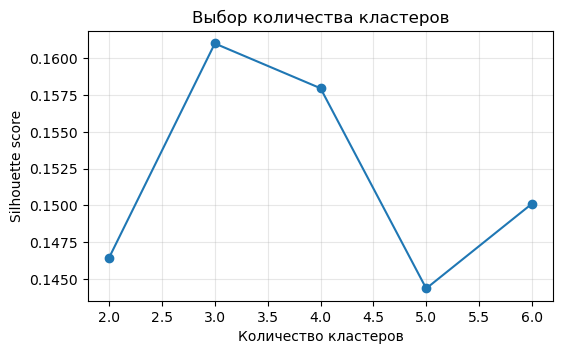

In [39]:
plt.figure(figsize=(6, 3.5))
plt.plot(cluster_scores['k'], cluster_scores['silhouette'], marker='o')

plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette score')
plt.title('Выбор количества кластеров')
plt.grid(alpha=0.3)

plt.show()

Выберем количество кластеров с наибольшим silhouette score среди проверенных вариантов, затем обучим K-means на всей базе клиентов.

In [40]:
best_k = int(cluster_scores.loc[cluster_scores['silhouette'].idxmax(), 'k'])
print('Выбрано кластеров:', best_k)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_data['cluster'] = kmeans.fit_predict(scaled)
clients['cluster'] = cluster_data['cluster'].values

print('\nЧисленность кластеров:\n')
print(clients['cluster'].value_counts().sort_index())

Выбрано кластеров: 3

Численность кластеров:

cluster
0    40066
1    37656
2    26715
Name: count, dtype: int64


In [41]:
cluster_summary = cluster_data.groupby('cluster').agg(
    clients=('id', 'size'),
    age=('age', 'median'),
    purchases=('purchase_count', 'mean'),
    spending=('total_spend', 'mean'),
    sale_share=('sale_share', 'mean'),
    male_share=('male_share', 'mean'),
    recency=('recency', 'mean')
)

display(cluster_summary.round(2))

,clients,age,purchases,spending,sale_share,male_share,recency
cluster,,,,,,,
0,40066,37.0,3.34,15865.47,0.25,0.46,24.66
1,37656,37.0,12.48,77481.84,0.33,0.46,9.44
2,26715,40.0,6.60,25043.77,0.44,0.06,16.97


Посмотрим товарные категории каждого кластера. Здесь категория приблизительно определена по первому слову названия товара; для общего сравнения ассортимента этого достаточно.

In [42]:
cluster_purchases = country_purchases.merge(clients[['id', 'cluster']], on='id', how='left')
category_table = pd.crosstab(cluster_purchases['cluster'], cluster_purchases['category'])

for number in sorted(clients['cluster'].unique()):
    print('Кластер', number)
    display(category_table.loc[number].sort_values(ascending=False).head(5))

Кластер 0


category
кроссовки    22334
шорты         6750
брюки         6743
футболка      6571
кеды          6484
Name: 0, dtype: int64

Кластер 1


category
кроссовки      62066
брюки          27522
футболка       25579
шорты          20859
полуботинки    20782
Name: 1, dtype: int64

Кластер 2


category
кроссовки    24289
брюки        12347
футболка     11279
сандалии      9364
кеды          8773
Name: 2, dtype: int64

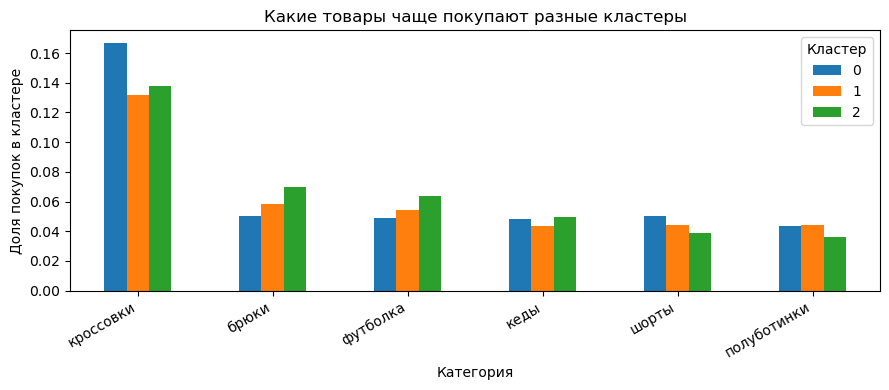

In [43]:
popular_categories = country_purchases['category'].value_counts().head(6).index
category_shares = pd.crosstab(cluster_purchases['cluster'], cluster_purchases['category'], normalize='index')
category_shares[popular_categories].T.plot(kind='bar', figsize=(9, 4))

plt.title('Какие товары чаще покупают разные кластеры')
plt.ylabel('Доля покупок в кластере')
plt.xlabel('Категория')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Кластер')

plt.tight_layout()
plt.show()

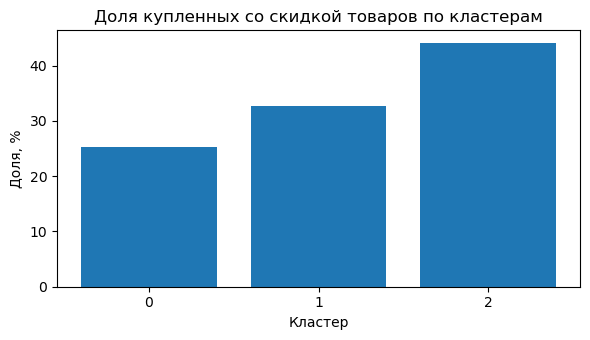

In [44]:
plot_bar(
    cluster_summary.index.astype(str), cluster_summary['sale_share'] * 100,
    'Доля купленных со скидкой товаров по кластерам', 'Кластер', 'Доля, %'
)

Сравним долю покупок со скидкой между кластерами и определим подходящие предложения для каждой группы клиентов

In [45]:
clients[['id', 'cluster']].to_csv('Кластеры клиентов.csv', index=False)
print('Номера кластеров сохранены.')

Номера кластеров сохранены.


## Модель склонности к покупке для города 1188

Построим модель для конкретного товара «Брюки мужские Demix». Цель – определить, кто купил товар в дни 31-58 по признакам, доступным до конца дня 30. Город 1188 не включаем в обучение, так как нужен прогноз именно для него.

In [46]:
sku = 'брюки мужские demix'
print('Покупок выбранного товара:', (country_purchases['product_clean'] == sku).sum())
print('Уникальных покупателей этого товара:', country_purchases.loc[
    country_purchases['product_clean'] == sku, 'id'
].nunique())

Покупок выбранного товара: 4919
Уникальных покупателей этого товара: 3526


In [47]:
history = country_purchases[country_purchases['dt'] <= 30].copy()
history['is_sku'] = (history['product_clean'] == sku).astype(int)
history['is_trousers'] = (history['category'] == 'брюки').astype(int)
history['is_male_item'] = (history['product_sex'] == 1).astype(int)
history['is_female_item'] = (history['product_sex'] == 0).astype(int)

display(history.head(3))

,id,product,colour,cost,product_sex,base_sale,dt,product_clean,category,colour_clean,male_item,female_item,is_sku,is_trousers,is_male_item,is_female_item
0,0,"Велосипед горный женский Stern Mira 2.0 26""",белый/синий,13599,0,1,7,"велосипед горный женский stern mira 2.0 26""",велосипед,белый,0,1,0,0,0,1
3,3,Бутсы мужские GSD Astro,белый,1599,1,0,13,бутсы мужские gsd astro,бутсы,белый,1,0,0,0,1,0
4,3,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мультицвет,7199,-1,0,27,мяч футбольный puma teamfinal 21.2 fifa qualit...,мяч,мультицвет,0,0,0,0,0,0


In [48]:
history_stats = history.groupby('id').agg(
    prev_items=('cost', 'size'),
    prev_spend=('cost', 'sum'),
    prev_avg_cost=('cost', 'mean'),
    prev_sale_share=('base_sale', 'mean'),
    prev_male_share=('is_male_item', 'mean'),
    prev_female_share=('is_female_item', 'mean'),
    prev_sku=('is_sku', 'sum'),
    prev_trousers=('is_trousers', 'sum'),
    prev_last_day=('dt', 'max')
)

display(history_stats.head())

,prev_items,prev_spend,prev_avg_cost,prev_sale_share,prev_male_share,prev_female_share,prev_sku,prev_trousers,prev_last_day
id,,,,,,,,,
0,1,13599,13599.000000,1.0,0.0,1.0,0,0,7
3,2,8798,4399.000000,0.0,0.5,0.0,0,0,27
4,6,28094,4682.333333,0.0,0.0,0.0,0,0,2
6,15,84085,5605.666667,0.4,0.6,0.0,0,2,30
7,3,14497,4832.333333,0.0,0.0,0.0,0,0,14


In [49]:
model_data = clients[['id', 'age', 'higher_education', 'personal_coef', 'city']].copy()
model_data = model_data.merge(history_stats, left_on='id', right_index=True, how='left')
model_data[history_stats.columns] = model_data[history_stats.columns].fillna(0)
model_data.loc[model_data['prev_items'] == 0, 'prev_last_day'] = -1
print('Размер таблицы признаков:', model_data.shape)

Размер таблицы признаков: (104437, 14)


В модель также включены признаки участия клиента в первой маркетинговой кампании и проживания в городе 1134, где проводилась вторая кампания

In [50]:
model_data['email_test'] = model_data['id'].isin(positive_ids).astype(int)
model_data['email_control'] = model_data['id'].isin(negative_ids).astype(int)
model_data['billboard_city'] = (model_data['city'] == 1134).astype(int)
future = country_purchases[country_purchases['dt'].between(31, 58)]
bought_ids = future.loc[future['product_clean'] == sku, 'id'].unique()
model_data['target'] = model_data['id'].isin(bought_ids).astype(int)

print('Доля покупателей выбранного товара:', round(model_data['target'].mean() * 100, 2), '%')

Доля покупателей выбранного товара: 1.32 %


In [51]:
model_features = [
    'age', 'higher_education', 'personal_coef',
    'prev_items', 'prev_spend', 'prev_avg_cost', 'prev_sale_share',
    'prev_male_share', 'prev_female_share', 'prev_sku', 'prev_trousers',
    'prev_last_day', 'email_test', 'email_control', 'billboard_city'
]

train_city = model_data[model_data['city'] != 1188]
city_1188 = model_data[model_data['city'] == 1188]

print('Остальные города:', len(train_city))
print('Город 1188:', len(city_1188))

Остальные города: 91999
Город 1188: 12438


Разделим данные на обучающую (80%) и тестовую (20%) выборки для оценки качества модели.

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    train_city[model_features], train_city['target'],
    test_size=0.2, stratify=train_city['target'], random_state=42
)

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)
print('Доля класса 1 в тесте:', round(y_test.mean() * 100, 2), '%')

Обучающая выборка: (73599, 15)
Тестовая выборка: (18400, 15)
Доля класса 1 в тесте: 1.35 %


In [53]:
purchase_model = RandomForestClassifier(
    n_estimators=130, max_depth=11, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)

purchase_model.fit(X_train, y_train)
purchase_score = purchase_model.predict_proba(X_test)[:, 1]

print('ROC-AUC:', round(roc_auc_score(y_test, purchase_score), 4))

ROC-AUC: 0.7302


Сравним долю покупателей товара среди 10% клиентов с самыми высокими оценками модели со средней долей покупателей в тестовой выборке.

In [54]:
top_threshold = np.quantile(purchase_score, 0.9)
top_buy_rate = y_test[purchase_score >= top_threshold].mean()
average_buy_rate = y_test.mean()

print('Покупка в тестовой выборке:', round(average_buy_rate * 100, 2), '%')
print('Покупка в верхних 10%:', round(top_buy_rate * 100, 2), '%')
print('Отношение частот (lift):', round(top_buy_rate / average_buy_rate, 2))

Покупка в тестовой выборке: 1.35 %
Покупка в верхних 10%: 4.95 %
Отношение частот (lift): 3.65


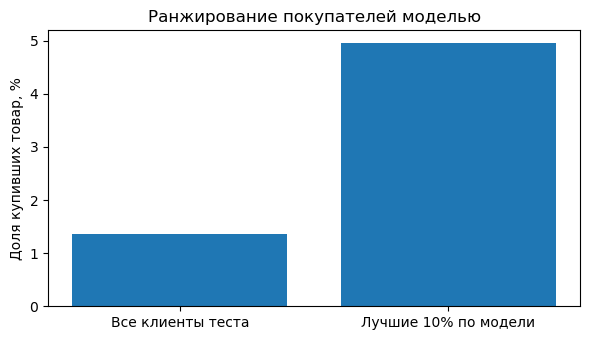

In [55]:
plot_bar(
    ['Все клиенты теста', 'Лучшие 10% по модели'],
    [average_buy_rate * 100, top_buy_rate * 100],
    'Ранжирование покупателей моделью', '', 'Доля купивших товар, %'
)

In [56]:
feature_importance = pd.Series(
    purchase_model.feature_importances_, index=model_features
).sort_values(ascending=False)

display(feature_importance.head(8).round(3))

prev_sku           0.217
prev_avg_cost      0.120
prev_spend         0.114
prev_items         0.097
prev_male_share    0.084
age                0.077
prev_last_day      0.070
prev_trousers      0.067
dtype: float64

Получим оценки модели для клиентов города 1188 и отсортируем клиентов по убыванию этих оценок. Это позволит определить, кому в первую очередь предлагать выбранный товар.

In [57]:
city_scores = city_1188[['id', 'city', 'age']].copy()
city_scores['purchase_score'] = purchase_model.predict_proba(city_1188[model_features])[:, 1]

city_scores = city_scores.sort_values('purchase_score', ascending=False)
display(city_scores.head(10))

,id,city,age,purchase_score
22983,46035,1188,36,0.490588
8440,16910,1188,67,0.470748
13522,27077,1188,49,0.408953
49399,99254,1188,58,0.334668
44664,89802,1188,37,0.295047
52889,106296,1188,22,0.287746
76079,152657,1188,37,0.278077
65886,132333,1188,48,0.261894
86300,173193,1188,41,0.259315
2187,4338,1188,37,0.254070


In [58]:
city_scores.to_csv('Рейтинг клиентов города 1188.csv', index=False)
print('Сохранён список клиентов города 1188, сортированный по оценке модели.')

Сохранён список клиентов города 1188, сортированный по оценке модели.


## Итоги

1. Профили страны 32 объединены, данные покупок обработаны; восстановление пола проверено F1 на отложенной выборке.
2. Для email-кампании обнаружено значимое различие между контрольной и тестовой группами ещё до её начала. Признать кампанию эффективной по этому сравнению нельзя.
3. Выделены кластеры с разной частотой покупок, товарными предпочтениями и долями скидок. Предложения нужно подбирать отдельно для каждой группы.
4. Для города 1188 рекомендуется начать с рекламной кампании на ограниченной аудитории клиентов с высокими оценками модели и оценить результаты с помощью A/B-теста.